# Can Medical Reasoning Be Compressed? Teaching Small Models to Think Clinically Through Distillation
Hochschule Heilbronn


Authors: 
- Alexia Lozano
- Pratik Manandhar 

## Abstract: 

This notebook presents a knowledge distillation pipeline, a model compression technique in which a smaller student model learns from a larger teacher model. Different distillation strategies are evaluated, including black-box distillation and logits-based distillation, under various training configurations.

The experiments are conducted on a medical question-answering dataset derived from the German Staatsexamen (state examination), requiring domain-specific medical knowledge. The main objective is to investigate whether knowledge distillation can improve the efficiency of smaller models while preserving the performance of larger ones.

Results show that the student's initial capabilities play a crucial role in the effectiveness of distillation. Furthermore, the student's learning is strongly limited by the teacher's accuracy, as incorrect teacher predictions are often transferred to the student. Although distillation leads to performance improvements in some settings, the student models are ultimately unable to match the performance of the teacher, highlighting both the potential and the limitations of knowledge distillation for specialized medical tasks.

In [ ]:
!nvidia-smi

In [41]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "3" 
os.environ["WORLD_SIZE"] = "1"
os.environ["RANK"] = "0"
os.environ["MASTER_ADDR"] = "localhost"
os.environ["MASTER_PORT"] = "12355"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["NCCL_DEBUG"] = "VERSION"

DATE = "26_06"

BASE_PATH = f"deeplearning_1/outputs/models"

# Hugging face token with access to the teacher and student models
HUGGING_FACE_TOKEN  = ""

# Flag to enable training on the student model
TRAIN_STUDENT = True

TEACHER_MODEL = "aaditya/OpenBioLLM-Llama3-8B"
STUDENT_MODEL = "meta-llama/Llama-3.2-1B-Instruct"

In [3]:
import pandas as pd
import re
import torch
from sklearn.model_selection import train_test_split
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)
from peft import LoraConfig, prepare_model_for_kbit_training
from trl import SFTConfig, SFTTrainer, DataCollatorForCompletionOnlyLM
import torch.nn.functional as F
from torch import nn

print("Torch:", torch.__version__, "| CUDA:", torch.cuda.is_available())

current_device =  lambda : 0

In [4]:
from huggingface_hub import login
import os
#The token should be indicated in the first cell of this notebook.
login(HUGGING_FACE_TOKEN)

## Shared prompt formatting

The functions `_clean_option()` and `parse_choices()` are responsible for converting the raw answer choices stored in the dataset into a standardized format that can be used by the model.

In [5]:
# --- MCQ option parsing -------------------------------------------------------
def _clean_option(c):
    """Strip whitespace/pipes and a leading marker like '0)', 'A.', '(b)'."""
    c = str(c).strip().strip("|").strip()
    c = re.sub(r'^\s*\(?[A-Ea-e0-9][\.\):]\s*', '', c).strip()
    return c

def parse_choices(raw):
    """Turn the 'Choices' field into a clean list of option strings."""
    import ast
    if raw is None or (isinstance(raw, float) and pd.isna(raw)):
        return []
    text = str(raw).strip()
    if not text:
        return []
    items = None
    if text[0] in "[(":
        try:
            parsed = ast.literal_eval(text)
            if isinstance(parsed, (list, tuple)):
                items = [str(c) for c in parsed]
        except (ValueError, SyntaxError):
            items = None
    if items is None and "|" in text:
        items = text.split("|")
    if items is None:
        parts = re.split(r'\s*(?:\(?[A-Ea-e0-9]\)|[A-Ea-e0-9][\.\):])\s+', text)
        parts = [p for p in parts if p and p.strip()]
        if len(parts) >= 2:
            items = parts
    if items is None:
        lines = [l for l in text.splitlines() if l.strip()]
        if len(lines) >= 2:
            items = lines
    if items is None:
        items = [text]
    return [c for c in (_clean_option(x) for x in items) if c]


PROMPT_STYLE = "strict"  # forces the model to answer with just the option number

def format_prompt(row, prompt_style="strict"):
    """Build the MCQ question text. Reads options from 'Choices'
    (falling back to 'Answer 1'..'Answer 5')."""
    case = str(row.get('Case', '')) if pd.notna(row.get('Case', '')) else ''
    question = str(row.get('Question', '')) if pd.notna(row.get('Question', '')) else ''

    choices = []
    for i in range(1, 6):
        col = f'Answer {i}'
        if col in row and pd.notna(row[col]):
            choices.append(_clean_option(row[col]))
    if not choices and 'Choices' in row and pd.notna(row['Choices']):
        choices = parse_choices(row['Choices'])
    choices = [c for c in choices if c]

    choices_str = "".join(f"{i}. {c}\n" for i, c in enumerate(choices))

    if prompt_style == "few_shot":
        prompt = f"""Answer medical multiple choice questions with ONLY the option number (0-4).

Example 1:
What is the capital of France?
0. Berlin
1. Paris
2. London
Answer: 1

Example 2:
What color is blood?
0. Blue
1. Green
2. Red
Answer: 2

Now answer this question:
{case}
{question}

{choices_str}
Answer:"""
        
    elif prompt_style == "concise":
        # Concise prompt
        prompt = f"""Question: {case} {question}

{choices_str}
Reply with only the number (0-4):"""

    elif prompt_style == "strict":
        prompt = f"""Answer medical multiple choice questions with ONLY the option number(0-4).

Example:
What is the first-line treatment for anaphylaxis?
0. Oral antihistamine
1. Intramuscular adrenaline
2. Inhaled corticosteroid
3. Intravenous fluids
4. Oxygen by mask
Answer: 1

Now answer this question:
{case}
{question}

{choices_str}
Answer:"""
    else:
        prompt = f"""Question: {case} {question}

{choices_str}Reply with only the option number:"""
    return prompt, choices


# --- Llama-3 chat wrapping ----------------------------------------------------
# We build the chat turns manually (NOT via apply_chat_template) so that training
# and eval use identical formatting and no surprise system prompt is injected.
# We intentionally omit <|begin_of_text|>: the tokenizer adds exactly one BOS, so
# train and eval both get a single BOS (the old notebook double-counted it in train).
ASSISTANT_HEADER = "<|start_header_id|>assistant<|end_header_id|>\n\n"

def wrap_user(user_content):
    # return user_content 
    """Wrap a user message and open the assistant turn (for generation)."""
    return (
        "<|start_header_id|>user<|end_header_id|>\n\n"
        f"{user_content}<|eot_id|>\n\n" + ASSISTANT_HEADER
    )

def extract_answer(text):
    """Extract an option index 0-4 from model output."""
    text = text.strip()
    if not text:
        return -1
    if text[0] in '01234':
        return int(text[0])
    patterns = [
        r'(?:answer|antwort|option|nummer|number)[:\s]*([0-4])',
        r'(?:ist|is)[:\s]*([0-4])',
        r'\(([0-4])\)',
        r'^([0-4])[.\s\)]',
        r'(?:^|\s)([0-4])(?:\s|$|\.)',
    ]
    for pattern in patterns:
        m = re.search(pattern, text, re.IGNORECASE)
        if m:
            return int(m.group(1))
    for ch in text:
        if ch in '01234':
            return int(ch)
    return -1

print("Prompt utilities loaded.")

Prompt utilities loaded.


## Staatsexamen Dataset

The experiments use a dataset of **12,467 multiple-choice questions** derived from the German medical *Staatsexamen*. Each sample contains a clinical **Case**, the **Question**, and the available **Choices**, which are formatted into prompts using the helper functions described previously.

Additionally, the dataset provides the **ground-truth label**, corresponding to the index of the correct answer. This label is used to compute the supervised loss during training and should not be confused with the teacher's prediction.

For training, each example is formatted as a complete Llama-3 conversation. The user message contains the multiple-choice question, while the assistant response consists only of the correct answer index (0--4). This structure ensures consistency between training and evaluation and allows direct comparison between teacher and student predictions during knowledge distillation.

In [6]:

staadt_df = pd.read_csv(
    "knowledge-distillation-for-llm-compression-from-theory-to-black-box-medical-qa/logs/OpenBioLLM_results.csv"
) 
print(staadt_df.shape)
print(staadt_df.columns.tolist())
staadt_df.head(5)


(12467, 11)
['Question_No', 'Case', 'Question', 'Choices', 'Correct_Answer_Index', 'Correct_Answer', 'Model_Prediction_Index', 'Model_Answer', 'Model_Raw_Output', 'Is_Correct', 'Model']


,Question_No,Case,Question,Choices,Correct_Answer_Index,Correct_Answer,Model_Prediction_Index,Model_Answer,Model_Raw_Output,Is_Correct,Model
0,1,NaN,Which of the aforementioned tests is most like...,0) Spirometry | 1) Blood gas analysis | 2) Che...,2,Chest X-ray,4,Blood test,4. Blood test,False,OpenBioLLM
1,2,NaN,"Based on the examination results, a diagnosis ...",0) outpatient vs. inpatient treatment | 1) adv...,0,outpatient vs. inpatient treatment,4,the information of the health authority (in ac...,4. the information of the health authority (,False,OpenBioLLM
2,3,NaN,Which of the following bacteria is the most li...,0) Staphylococcus aureus | 1) Mycoplasma pneum...,3,Streptococcus pneumoniae,3,Streptococcus pneumoniae,3. Streptococcus pneumoniae,True,OpenBioLLM
3,4,NaN,Which of the following antibiotics should most...,0) Ofloxacin | 1) Amoxicillin | 2) Meropenem |...,1,Amoxicillin,3,Cefotaxime,3. Cefotaxime,False,OpenBioLLM
4,5,NaN,"The patient, whose adherence to medication reg...",0) Discontinue rivaroxaban administration from...,2,Last dose of rivaroxaban on the day before sur...,4,Administration of rivaroxaban on the day of su...,4,False,OpenBioLLM


In [7]:
# 70% train / 30% eval, same seed as before so the eval split is comparable
staadt_train, staadt_eval = train_test_split(staadt_df, test_size=0.3, random_state=42)

# Eval needs the ground-truth index under the name the eval loop expects.
staadt_eval = staadt_eval.copy()
staadt_eval["Correct Answer"] = staadt_eval["Correct_Answer_Index"]

print("train:", staadt_train.shape, "| eval:", staadt_eval.shape)


train: (8726, 11) | eval: (3741, 12)


`build_training_text()`: This function builds the final training samples used for fine-tuning the model. For each row in the dataset, it extracts the correct answer index (Correct_Answer_Index) and checks that it is valid.

Each question is first formatted into a multiple-choice prompt using format_prompt, which includes the case, question, and answer options. Then the prompt is wrapped into the Llama-3 chat format using wrap_user, so it matches the structure expected by the model during training.

The final training example consists of the full prompt followed by the correct answer index (0–4) and the end-of-turn token. This means the model is trained to directly generate only the correct option number.

Invalid samples (missing labels or wrong indices) are removed to ensure data quality. All valid examples are then stored in a HuggingFace Dataset for training.

Finally, the RESPONSE_TEMPLATE is defined to ensure that the loss is computed only on the assistant’s answer, not on the prompt.

In [8]:
# Build MCQ-aligned training text: user = eval prompt, assistant = correct digit.

def build_training_text(row):
    
    idx = row["Correct_Answer_Index"]
    if pd.isna(idx):
        return None
    idx = int(idx)
    
    prompt, choices = format_prompt(row, prompt_style=PROMPT_STYLE)

    
    if not (0 <= idx < len(choices)):   # index must point at a real option
        return None
    # assistant turn is just the option number
    return wrap_user(prompt) + f"{idx}<|eot_id|>"

texts = [build_training_text(r) for _, r in staadt_train.iterrows()]
texts = [t for t in texts if t is not None]
print(f"usable training examples: {len(texts)} / {len(staadt_train)}")

train_dataset = Dataset.from_dict({"text": texts})

# Sanity-check one example end-to-end.
print("\n----- sample training example -----")
print(train_dataset[0]['text'])

# This is the unique marker the collator uses to mask the prompt so loss/KD land
# ONLY on the answer tokens (the digit + <|eot_id|>).
# Everything before this template is the prompt, and everything after the template is the anser
RESPONSE_TEMPLATE = ASSISTANT_HEADER

print("\n----- Response Template -----")
RESPONSE_TEMPLATE



usable training examples: 8726 / 8726

----- sample training example -----
<|start_header_id|>user<|end_header_id|>

Answer medical multiple choice questions with ONLY the option number(0-4).

Example:
What is the first-line treatment for anaphylaxis?
0. Oral antihistamine
1. Intramuscular adrenaline
2. Inhaled corticosteroid
3. Intravenous fluids
4. Oxygen by mask
Answer: 1

Now answer this question:

In the sinusoids between the liver cell trabeculae, fluid flows

0. Bile flow towards the central vein
1. Arterial blood towards Glisson's triad
2. Mixed arterial and venous blood flowing towards the central vein
3. venous blood towards Glisson's triad
4. Mixed arterial and venous blood flowing towards Glisson's triad

Answer:<|eot_id|>

<|start_header_id|>assistant<|end_header_id|>

2<|eot_id|>

----- Response Template -----


'<|start_header_id|>assistant<|end_header_id|>\n\n'

## Load teacher and Student
The teacher model used in the experiments is `aaditya/OpenBioLLM-Llama3-8B` (frozen and used only for inference), while the student model is `meta-llama/Llama-3.2-1B-Instruct`. Both models are loaded in 4-bit precision to reduce memory usage and allow efficient training.

Since both models are based on the Llama-3 architecture, they share the same 128k-token vocabulary, which makes logit-level knowledge distillation (KL divergence over output distributions) well-defined and consistent.

After testing different student model sizes, this notebook focuses on the 1B parameter model as the main experimental setting. However, additional experiments were also conducted using a 3B parameter student, the results are shown in the final version of the paper.

In [9]:
model_id_teacher = TEACHER_MODEL
model_id_student = STUDENT_MODEL

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,   # match bf16 training
)

device_actual = torch.cuda.current_device()

teacher_model = AutoModelForCausalLM.from_pretrained(
    model_id_teacher, quantization_config=bnb_config, device_map={"": current_device()}
)
teacher_model.eval()

student_model = AutoModelForCausalLM.from_pretrained(
    model_id_student, quantization_config=bnb_config, device_map={"": current_device()}
)
student_model = prepare_model_for_kbit_training(student_model)

# Both models use the same Llama-3 tokenizer; right padding for training.
tokenizer = AutoTokenizer.from_pretrained(model_id_teacher)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

# Verify vocab match (required for the KL term to be meaningful).
print("teacher vocab:", teacher_model.config.vocab_size,
      "| student vocab:", student_model.config.vocab_size)

Loading checkpoint shards: 100%|██████████| 4/4 [00:06<00:00,  1.75s/it]


teacher vocab: 128256 | student vocab: 128256


## Knowledge-distillation Trainer

This trainer implements a knowledge distillation framework where a frozen teacher model guides a student model by transferring soft probability distributions over multiple-choice answers, while also using supervised ground-truth labels. The implementation ensures proper alignment between teacher and student by correcting prompt formatting, tokenization inconsistencies, and per-sample answer positioning, resulting in a stable and task-specific distillation objective.

In [46]:

class KnowledgeDistillationTrainer(SFTTrainer):
    def __init__(self, teacher_model, temperature=2.0, alpha=0.5, num_options=5, debug_logs=False,
                 *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.teacher_model = teacher_model
        self.teacher_model.eval()                      # no dropout in the KD target
        for p in self.teacher_model.parameters():
            p.requires_grad_(False)
        self.temperature = temperature
        self.alpha = alpha
        self.num_options = num_options
        self.kl_loss = nn.KLDivLoss(reduction="batchmean")
        self._option_token_ids = None                  # built lazily on first batch
        self.debug_logs = debug_logs
        # Matches wrap_user()'s opening tag; used to recover the raw user prompt
        # from the decoded (wrapped) student input below.
        self._user_header = "<|start_header_id|>user<|end_header_id|>\n\n"

    def _build_option_ids(self, gold_token_id):
        """Pick the digit-token variant (bare '0' vs space-prefixed ' 0') that
        matches how answers actually tokenize in the data, then verify the gold
        token is in the set."""
        tok = self.processing_class
        candidates = [
            [tok.encode(f" {i}", add_special_tokens=False)[-1] for i in range(self.num_options)],
            [tok.encode(str(i),  add_special_tokens=False)[-1] for i in range(self.num_options)],
        ]
        for ids in candidates:
            if gold_token_id in ids:
                return ids
        raise ValueError(
            f"gold answer token {gold_token_id} "
            f"({tok.decode([gold_token_id])!r}) not in any option-id set {candidates}"
        )

    def _raw_prompt_from_wrapped(self, input_ids_row):
        """Recover the bare user prompt (no Llama-3 chat special tokens) from a
        wrap_user()-wrapped training example, by decoding and slicing out the
        text between the user header and the following <|eot_id|>."""
        text = self.processing_class.decode(input_ids_row, skip_special_tokens=False)
        start = text.index(self._user_header) + len(self._user_header)
        end = text.index("<|eot_id|>", start)
        return text[start:end]

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs["labels"]

        # ---- Student: standard masked CE over the answer span (wrapped format,
        # matching how it's trained/evaluated) ----
        outputs_student = model(**inputs)
        student_logits = outputs_student.logits
        loss_ce = outputs_student.loss
        input_text = self.processing_class.batch_decode(
            inputs["input_ids"],
            skip_special_tokens=False
        )
        
        if self.debug_logs:
            print("INPUT:")
            print(input_text[0])

       
        shift_student = student_logits[:, :-1, :]
        shift_labels  = labels[:, 1:]
        mask = shift_labels != -100                    # True only on answer tokens

        device = student_logits.device
        loss_distill = torch.zeros((), device=device, dtype=student_logits.dtype)

        # ---- Teacher: its OWN raw/unwrapped prompt, not the student's wrapped
        # input. Llama-3 chat-wrapping degrades this teacher to near-zero accuracy
        # (verified at eval), so feeding it the wrapped format here would distill
        # from a confused teacher instead of the competent one. ----
        raw_prompts = [
            self._raw_prompt_from_wrapped(inputs["input_ids"][i])
            for i in range(inputs["input_ids"].size(0))
        ]
        tok = self.processing_class
        teacher_inputs = tok(
            raw_prompts, return_tensors="pt", padding=True, truncation=True, max_length=1024
        ).to(device)

        with torch.no_grad():
            teacher_out_logits = self.teacher_model(**teacher_inputs).logits

        # Last real (non-pad) token of each raw prompt predicts the answer digit.
        teacher_last_pos = teacher_inputs["attention_mask"].sum(dim=1) - 1
        teacher_answer_logits = teacher_out_logits[
            torch.arange(teacher_out_logits.size(0), device=device), teacher_last_pos
        ]  # [B, vocab]

        # Per-example answer position (the fix: never reuse example-0's index)
        s_rows, t_rows = [], []
        for i in range(shift_labels.size(0)):
            row = mask[i]
            if not row.any():
                continue
            pos = torch.where(row)[0][0]               # first answer token of THIS example
            gold = shift_labels[i, pos].item()

            if self.debug_logs:
                print("gold:",gold)
            
            option_token_ids = [
                tok.encode(str(j), add_special_tokens=False)[0]
                for j in range(5)
            ]

            if self._option_token_ids is None:
                self._option_token_ids = self._build_option_ids(gold)
            opt = self._option_token_ids

            s_rows.append(shift_student[i, pos, opt])           # [num_options]
            t_rows.append(teacher_answer_logits[i, opt])        # [num_options]

        if s_rows:
            student_opt = torch.stack(s_rows)                   # [B', num_options]
            teacher_opt = torch.stack(t_rows)
            gt = gold  # ONLY if gold is already 0–4 (important!)

            student_probs = F.softmax(student_opt[i], dim=-1)
            teacher_probs = F.softmax(teacher_opt[i], dim=-1)
            
            student_pred = torch.argmax(student_probs).item()
            teacher_pred = torch.argmax(teacher_probs).item()
            
            if self.debug_logs:
                print("\n==============================")
            gt_tokens = labels[i][labels[i] != -100]

            gt_text = tokenizer.decode(gt_tokens, skip_special_tokens=True).strip()


           
            if self.debug_logs:
                print("Ground truth:", gt_text)
                print("Student:")
                print(" probs:", student_probs.tolist())
                print(" pred :", student_pred)
                
                print("Teacher:")
                print(" probs:", teacher_probs.tolist())
                print(" pred :", teacher_pred)
            log_soft_student = F.log_softmax(student_opt / self.temperature, dim=-1)
            soft_teacher     = F.softmax(teacher_opt / self.temperature, dim=-1)
        
            loss_distill = self.kl_loss(log_soft_student, soft_teacher) * (self.temperature ** 2)

        total_loss = (1 - self.alpha) * loss_ce + self.alpha * loss_distill
        
        if self.debug_logs:
            print("Cross entropy loss",loss_ce)
            print("distillation loss", loss_distill)
            print("total loss", total_loss.item())
        

        return (total_loss, outputs_student) if return_outputs else total_loss

## Hyperparameters and training

Stabilized: low LR, cosine schedule with warmup, gradient clipping, and KD weighted
below the CE term so the ground-truth answer leads and the teacher only nudges.

In [ ]:

peft_config = LoraConfig(
    r=16,
    lora_alpha=32,
    target_modules=["q_proj", "v_proj", "k_proj", "o_proj"], # The specific layers within the Transformer architecture where the LoRA adapters will be injected
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)

training_args = SFTConfig(
    output_dir=f"{BASE_PATH}/llama-3.2-1b-distilled",
    per_device_train_batch_size=1,        # 1 question per GPU
    gradient_accumulation_steps=20,       # 20 accumulated = 20 questions per step
    learning_rate=1e-4,
    bf16=True,
    logging_steps=20,
    report_to="none",
    warmup_ratio=0.03, 
    lr_scheduler_type="cosine", 
    max_grad_norm=0.3, 
    
    save_strategy="steps",
    save_steps=100,                      
    save_total_limit=None,
    
    # ─── TRAINING ───
    max_steps = 10, 
    # num_train_epochs = 3,
   
    gradient_checkpointing=True,
    max_seq_length=10000,
    dataset_text_field="text",
    ddp_find_unused_parameters=False,
    local_rank=-1
)

# Mask everything before the assistant header; loss/KD only on the answer.
collator = DataCollatorForCompletionOnlyLM(
    response_template=RESPONSE_TEMPLATE, # Denotes what to look for in the input to differentiate between prompt and answer
    tokenizer=tokenizer,
)


trainer = KnowledgeDistillationTrainer(
    model=student_model,
    teacher_model=teacher_model,
    temperature=2.0,
    alpha=0.5,
    train_dataset=train_dataset,
    peft_config=peft_config,
    tokenizer=tokenizer,
    args=training_args,
    data_collator=collator,
)

if TRAIN_STUDENT:
    trainer.train()


## Merge LoRA checkpoints into standalone models

Merges each saved checkpoint into a full FP16 model for evaluation. Auto-detects
whatever `checkpoint-*` folders actually exist instead of hard-coding step numbers.

In [ ]:
import os, gc, glob
from peft import PeftModel

ckpt_dir = f"{BASE_PATH}/llama-3.2-1b-distilled"
out_dir = f"{BASE_PATH}/final_student_models/{DATE}"
QUESTIONS_PER_STEP = 20   # per_device_batch (2) * grad_accum (8)
 
tok = AutoTokenizer.from_pretrained(model_id_student)
tok.pad_token = tok.eos_token

checkpoints = sorted(
    int(os.path.basename(p).split("-")[1])
    for p in glob.glob(os.path.join(ckpt_dir, "checkpoint-*"))
)

print("found checkpoints:", checkpoints)

for step in checkpoints:
    ruta = os.path.join(ckpt_dir, f"checkpoint-{step}")
    dest = os.path.join(out_dir, f"llama-student-questions-{step * QUESTIONS_PER_STEP}")
    print(f"\nMerging checkpoint-{step} ({step * QUESTIONS_PER_STEP} questions) -> {dest}")
    base = AutoModelForCausalLM.from_pretrained(
        model_id_student, torch_dtype=torch.float16, device_map={"": current_device()}
    )
    merged = PeftModel.from_pretrained(base, ruta).merge_and_unload()
    merged.save_pretrained(dest)
    tok.save_pretrained(dest)
    del merged, base
    gc.collect(); torch.cuda.empty_cache()

print("\nDone.")

found checkpoints: [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000, 1100, 1122]

Done.


## Evaluation

Uses the **same** `format_prompt` + `wrap_user` as training, so train and test
formatting are identical. Set `SAMPLE_SIZE` to evaluate on a subset for speed.

In [18]:
import gc
from tqdm import tqdm

def clear_gpu():
    gc.collect(); torch.cuda.empty_cache()

def get_model_answer(model, tokenizer, prompt, max_new_tokens=5):
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    gen = tokenizer.decode(outputs[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    return extract_answer(gen), gen.strip()

def evaluate_model(model, tokenizer, df, model_name, sample_size=None, debug_print=False, use_chat_template=True, use_wrap_user=False):
    """use_chat_template: use the tokenizer's own chat template (instruct models).
    use_wrap_user: use the same manual Llama-3 wrapping as training (the student).
    Leave both False for models prompted with the raw format_prompt text (e.g. the
    teacher, which was queried that way when OpenBioLLM_results.csv was generated)."""
    if sample_size:
        df = df.head(sample_size)
    results, correct, total = [], 0, len(df)
    print(f"\nEvaluating {model_name} on {total} questions...")
    for idx, row in tqdm(df.iterrows(), total=total, disable=debug_print):
        prompt, choices = format_prompt(row, prompt_style=PROMPT_STYLE)
        if use_chat_template:
            messages = [{"role": "assistant", "content": prompt}]
            prompt = tokenizer.apply_chat_template(
                messages,
                tokenize=False,
                add_generation_prompt=True
            )
        elif use_wrap_user:
            prompt = wrap_user(user_content=prompt)

        correct_idx = int(row['Correct_Answer_Index']) if pd.notna(row['Correct_Answer_Index']) else -1
        model_idx, raw = get_model_answer(model, tokenizer, prompt)
        is_correct = (model_idx == correct_idx)
        correct += int(is_correct)
        if debug_print:
            print(f"[{idx}] pred={model_idx} gold={correct_idx} raw={raw!r} "
                  f"{'OK' if is_correct else 'X'}")
        results.append({
            'Question_No': idx,
            'Correct_Answer_Index': correct_idx,
            'Model_Prediction_Index': model_idx,
            'Model_Raw_Output': raw,
            'Is_Correct': is_correct,
            'Model': model_name,
        })
    acc = correct / total * 100
    print(f"\n{model_name}: {correct}/{total} = {acc:.2f}%")
    return pd.DataFrame(results), acc

print("Evaluation functions loaded!")

Evaluation functions loaded!


In [23]:
# Evaluate teacher and distilled student model

SAMPLE_SIZE = 10
print(model_id_teacher)

base_eval = AutoModelForCausalLM.from_pretrained(
    model_id_teacher, device_map={"": current_device()}, torch_dtype=torch.float16
)
clear_gpu()
_, acc_base = evaluate_model(base_eval, tokenizer, staadt_eval,
                             "teacher", sample_size=SAMPLE_SIZE, debug_print=False, use_chat_template=False, use_wrap_user=True)
del base_eval
clear_gpu()


aaditya/OpenBioLLM-Llama3-8B


Loading checkpoint shards: 100%|██████████| 4/4 [00:06<00:00,  1.60s/it]



Evaluating teacher on 10 questions...


100%|██████████| 10/10 [00:02<00:00,  3.35it/s]



teacher: 2/10 = 20.00%


In [22]:
# Quick sanity peek: print raw outputs for the first few eval questions.

base_eval = AutoModelForCausalLM.from_pretrained(
    model_id_student, device_map={"": current_device()}, torch_dtype=torch.float16
)
clear_gpu()
_, acc_base = evaluate_model(base_eval, tokenizer, staadt_eval,
                             "base-untrained", sample_size=SAMPLE_SIZE, debug_print=False, use_chat_template=False, use_wrap_user=True)
del base_eval
clear_gpu()


Evaluating base-untrained on 10 questions...


100%|██████████| 10/10 [00:00<00:00, 10.93it/s]



base-untrained: 2/10 = 20.00%


In [20]:
# Baseline (untrained student) vs. distilled student, on the same sample.
# base_eval = AutoModelForCausalLM.from_pretrained(
#     model_id_student, device_map={"": current_device()}, torch_dtype=torch.float16
# )
# clear_gpu()
# res_base, acc_base = evaluate_model(base_eval, tokenizer, staadt_eval,
#                                     "base-untrained", sample_size=SAMPLE_SIZE, use_chat_template=False, use_wrap_user=True)
# del base_eval; clear_gpu()
# 
# Point this at the merged checkpoint you want to score.
import glob, os
merged_dirs = sorted(glob.glob(f"{BASE_PATH}/final_student_models/{DATE}/llama-student-questions-*"),
                     key=lambda p: int(p.split("-")[-1]))
# print(f"/home/jovyan/work/{BASE_PATH}/final_student_models/{DATE}/llama-student-preguntes-*")
print("available merged models:", merged_dirs)
print(merged_dirs)
trained_path = merged_dirs[-1]   # last checkpoint by default

trained = AutoModelForCausalLM.from_pretrained(trained_path, device_map={"": current_device()},
                                               torch_dtype=torch.float16)
clear_gpu()
res_trained, acc_trained = evaluate_model(trained, tokenizer, staadt_eval,
                                          os.path.basename(trained_path),
                                          sample_size=SAMPLE_SIZE, use_chat_template=False, use_wrap_user=True)
del trained; clear_gpu()

print(f"\nbase   : {acc_base:.2f}%")
print(f"trained: {acc_trained:.2f}%  ({trained_path})")


available merged models: ['deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-2000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-4000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-6000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-8000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-10000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-12000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-14000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-16000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-18000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-20000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-22000', 'deeplearn

  0%|          | 0/10 [00:00<?, ?it/s]/home/jovyan/work/deeplearning_project/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.6` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/home/jovyan/work/deeplearning_project/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
100%|██████████| 10/10 [00:00<00:00, 10.94it/s]



llama-student-questions-22440: 5/10 = 50.00%

base   : 20.00%
trained: 50.00%  (deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-22440)


checkpoints to evaluate: ['llama-student-questions-2000', 'llama-student-questions-4000', 'llama-student-questions-6000', 'llama-student-questions-8000', 'llama-student-questions-10000', 'llama-student-questions-12000', 'llama-student-questions-14000', 'llama-student-questions-16000', 'llama-student-questions-18000', 'llama-student-questions-20000', 'llama-student-questions-22000', 'llama-student-questions-22440']

Evaluating base-untrained on 3000 questions...


100%|██████████| 3000/3000 [04:23<00:00, 11.39it/s]



base-untrained: 736/3000 = 24.53%


Loading checkpoint shards: 100%|██████████| 4/4 [00:06<00:00,  1.61s/it]



Evaluating teacher on 3000 questions...


...


llama-student-questions-20000: 1295/3000 = 43.17%

Evaluating llama-student-questions-22000 on 3000 questions...


100%|██████████| 3000/3000 [04:23<00:00, 11.39it/s]



llama-student-questions-22000: 1289/3000 = 42.97%

Evaluating llama-student-questions-22440 on 3000 questions...


100%|██████████| 3000/3000 [04:24<00:00, 11.34it/s]



llama-student-questions-22440: 1292/3000 = 43.07%

  questions_seen  accuracy                         model  ci95_pp
              0 24.533333                base-untrained 1.539754
              1 56.433333                       teacher 1.774355
           2001 38.566667  llama-student-questions-2000 1.741821
           4001 39.666667  llama-student-questions-4000 1.750600
           6001 41.233333  llama-student-questions-6000 1.761510
           8001 41.433333  llama-student-questions-8000 1.762770
          10001 41.500000 llama-student-questions-10000 1.763183
          12001 42.266667 llama-student-questions-12000 1.767697
          14001 42.633333 llama-student-questions-14000 1.769701
          16001 42.900000 llama-student-questions-16000 1.771096
          18001 42.933333 llama-student-questions-18000 1.771267
          20001 43.166667 llama-student-questions-20000 1.772439
          22001 42.966667 llama-student-questions-22000 1.771437
          22441 43.066667 llama-stude

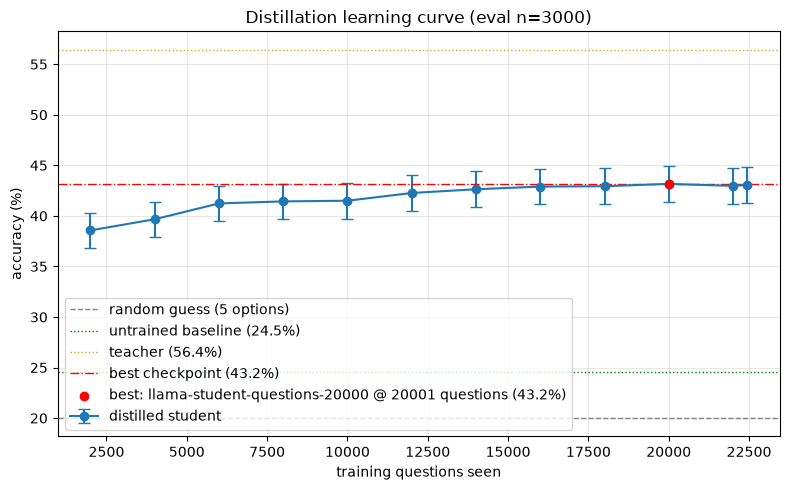

In [24]:
import glob, os
import matplotlib.pyplot as plt

CURVE_SAMPLE_SIZE = 3000 
INCLUDE_BASE = True         
INCLUDE_TEACHER = True

# Discover merged checkpoints, ordered by number of training questions seen.
merged_dirs = sorted(
    glob.glob(f"{BASE_PATH}/final_student_models/{DATE}/llama-student-questions-*"),
    key=lambda p: int(p.split("-")[-1]),
)
print("checkpoints to evaluate:", [os.path.basename(d) for d in merged_dirs])

curve = []   # rows of (questions_seen, accuracy, model_name)

# Optional anchor: untrained student = 0 questions seen.
if INCLUDE_BASE:
    base_eval = AutoModelForCausalLM.from_pretrained(
        model_id_student, device_map={"": current_device()}, torch_dtype=torch.float16
    )
    clear_gpu()
    _, acc0 = evaluate_model(base_eval, tokenizer, staadt_eval,
                             "base-untrained", sample_size=CURVE_SAMPLE_SIZE, use_chat_template=False, use_wrap_user=True)
    curve.append((0, acc0, "base-untrained"))
    del base_eval; clear_gpu()

if INCLUDE_TEACHER:
    teacher_eval  = AutoModelForCausalLM.from_pretrained(
        "aaditya/OpenBioLLM-Llama3-8B", device_map={"": current_device()}, torch_dtype=torch.float16
    )
    clear_gpu()
    _, acc_teach = evaluate_model(teacher_eval, tokenizer, staadt_eval, 'teacher', sample_size=CURVE_SAMPLE_SIZE, use_chat_template=False)

    curve.append((1, acc_teach, "teacher"))
    del teacher_eval; clear_gpu()

# Score each merged checkpoint, freeing GPU memory between models.
for d in  :
    questions_seen = int(d.split("-")[-1])
    model = AutoModelForCausalLM.from_pretrained(d, device_map={"": current_device()},
                                                 torch_dtype=torch.float16)
    clear_gpu()
    _, acc = evaluate_model(model, tokenizer, staadt_eval,
                            os.path.basename(d), sample_size=CURVE_SAMPLE_SIZE, use_chat_template=False, use_wrap_user=True)
    curve.append((questions_seen + 1, acc, os.path.basename(d)))
    del model; clear_gpu()

# Assemble the curve and a 95% confidence band (binomial normal approx).
curve_df = (pd.DataFrame(curve, columns=["questions_seen", "accuracy", "model"])
              .sort_values("questions_seen").reset_index(drop=True))
n = CURVE_SAMPLE_SIZE or len(staadt_eval)
p = curve_df["accuracy"] / 100.0
curve_df["ci95_pp"] = 1.96 * (p * (1.0 - p) / n) ** 0.5 * 100.0   # +/- percentage points

curve_df.to_csv(f"{BASE_PATH}/learning_curve_1.csv", index=False)
print("\n", curve_df.to_string(index=False))

# Best is taken only among the actual trained checkpoints (exclude base/teacher anchors).
checkpoint_rows = curve_df[~curve_df["model"].isin(["base-untrained", "teacher"])]
best = checkpoint_rows.loc[checkpoint_rows["accuracy"].idxmax()]
print(f"\nBest checkpoint: {best['model']} @ {int(best['questions_seen'])} questions "
      f"= {best['accuracy']:.2f}%  (eval n={n}, +/-{best['ci95_pp']:.1f} pp)")

# Plot accuracy vs. questions-seen with error bars, plus reference lines for
# base, teacher, and the best checkpoint so all three are visible on the curve.
plt.figure(figsize=(8, 5))
plt.errorbar(checkpoint_rows["questions_seen"], checkpoint_rows["accuracy"],
             yerr=checkpoint_rows["ci95_pp"], marker="o", capsize=4, label="distilled student")
plt.axhline(20, color="gray", ls="--", lw=1, label="random guess (5 options)")

if INCLUDE_BASE:
    acc_base_pt = curve_df.loc[curve_df["questions_seen"] == 0, "accuracy"].iloc[0]
    plt.axhline(acc_base_pt, color="green", ls=":", lw=1,
                label=f"untrained baseline ({acc_base_pt:.1f}%)")

if INCLUDE_TEACHER:
    acc_teach_pt = curve_df.loc[curve_df["questions_seen"] == 1, "accuracy"].iloc[0]
    plt.axhline(acc_teach_pt, color="goldenrod", ls=":", lw=1,
                label=f"teacher ({acc_teach_pt:.1f}%)")

plt.axhline(best["accuracy"], color="red", ls="-.", lw=1,
            label=f"best checkpoint ({best['accuracy']:.1f}%)")
plt.scatter([best["questions_seen"]], [best["accuracy"]], color="red", zorder=5,
            label=f"best: {best['model']} @ {int(best['questions_seen'])} questions ({best['accuracy']:.1f}%)")

plt.title(f"Distillation learning curve (eval n={n})")
plt.xlabel("training questions seen")
plt.ylabel("accuracy (%)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(f"{BASE_PATH}/learning_curve_1.png", dpi=120)
plt.show()

## Evaluating generic medical questions

After training the different models, there is substantial improvement in accuracy when answering questions from the German Staatsexamen. Next, the teacher, baseline student and the distilled student are further given generic questions that are generated from ChatGPT to check if the distillation process improves the student model's accuracy overall.

#### Prepare LLM generated dataset

In [25]:
import re
import pandas as pd
import torch
import gc
from tqdm import tqdm

# --- Parse medical_mcq_1000.csv into question text + choices -----------------

def parse_mcq_row(raw_question):
    """Split '[specialty] Question text 0) opt0 | 1) opt1 | ...' into
    (question_text, [opt0, opt1, ...])."""
    text = raw_question.strip()
    text = re.sub(r'^\[[^\]]+\]\s*', '', text)  # drop leading "[specialty] "
    parts = re.split(r'\s*\|\s*', text)
    # First part still has "question stem 0) first option"
    m = re.match(r'^(.*?)\s*0\)\s*(.*)$', parts[0], flags=re.DOTALL)
    if not m:
        raise ValueError(f"Could not parse stem/option 0 from: {parts[0]!r}")
    question_stem, opt0 = m.group(1).strip(), m.group(2).strip()
    choices = [opt0]
    for p in parts[1:]:
        m2 = re.match(r'^\d+\)\s*(.*)$', p.strip())
        choices.append(m2.group(1).strip() if m2 else p.strip())
    return question_stem, choices

def load_medical_mcq(csv_path):
    df = pd.read_csv(csv_path)
    stems, choice_lists = [], []
    for q in df['question']:
        stem, choices = parse_mcq_row(q)
        stems.append(stem)
        choice_lists.append(choices)
    df = df.copy()
    df['Question'] = stems
    df['Case'] = ''
    df['Choices'] = choice_lists
    df['Correct_Answer_Index'] = df['answer'].astype(int)
    return df

mcq_df = load_medical_mcq("deeplearning/Code_versions/medical_mcq_1000.csv")
mcq_df = mcq_df.drop(columns = ['question', 'answer'])
print(mcq_df.shape)
mcq_df.head(5)

(1000, 4)


,Question,Case,Choices,Correct_Answer_Index
0,How is meningitis diagnosed?,,[lumbar appendectomy after imaging confirmatio...,1
1,What is the first-line management of Crohn dis...,,"[chest X-ray and sputum culture, abnormal elec...",4
2,What is a key complication of diabetic ketoaci...,,[insulin infusion with fluid and electrolyte r...,0
3,What is the first-line management of iron defi...,,[CT brain without contrast to differentiate is...,4
4,What is the treatment of Crohn disease?,,"[CSF analysis via lumbar puncture, insulin inf...",4


#### Evaluating 1000 LLM generated medical questions

In [27]:
def get_model_answer(model, tokenizer, prompt, max_new_tokens=5):
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=1024)
    inputs = {k: v.to(model.device) for k, v in inputs.items()}
    with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.bfloat16):
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    gen = tokenizer.decode(outputs[0][inputs['input_ids'].shape[1]:], skip_special_tokens=True)
    return extract_answer(gen), gen.strip()

def format_prompt_mcq(row, prompt_style="strict"):
    """Like format_prompt(), but for rows where 'Choices' is already a
    Python list (avoids pd.notna() ambiguity on list-valued cells)."""
    question = str(row['Question'])
    choices = [c for c in row['Choices'] if c]
    choices_str = "".join(f"{i}. {c}\n" for i, c in enumerate(choices))
    if prompt_style == "strict":
        prompt = f"""Answer medical multiple choice questions with ONLY the option number(0-4).

Example:
What is the first-line treatment for anaphylaxis?
0. Oral antihistamine
1. Intramuscular adrenaline
2. Inhaled corticosteroid
3. Intravenous fluids
4. Oxygen by mask
Answer: 1

Now answer this question:
{question}

{choices_str}
Answer:"""
    else:
        prompt = f"""Question: {question}

{choices_str}Reply with only the option number:"""
    return prompt, choices


def evaluate_model_mcq(model, tokenizer, df, model_name, sample_size=None,
                     use_chat_template=False, use_wrap_user=True, debug_print=False):
    if sample_size:
        df = df.head(sample_size)
    results, correct, total = [], 0, len(df)
    print(f"\nEvaluating {model_name} on {total} questions...")
    for idx, row in tqdm(df.iterrows(), total=total, disable=debug_print):
        prompt, choices = format_prompt_mcq(row, prompt_style=PROMPT_STYLE)
        # print(prompt)
        if use_chat_template:
            messages = [{"role": "assistant", "content": prompt}]
            prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
        elif use_wrap_user:
            prompt = wrap_user(user_content=prompt)

        correct_idx = int(row['Correct_Answer_Index'])
        model_idx, raw = get_model_answer(model, tokenizer, prompt)
        is_correct = (model_idx == correct_idx)
        correct += int(is_correct)
        if debug_print:
            print(f"[{idx}] pred={model_idx} gold={correct_idx} raw={raw!r} "
                  f"{'OK' if is_correct else 'X'}")
        results.append({
            'Question_No': idx,
            'Correct_Answer_Index': correct_idx,
            'Model_Prediction_Index': model_idx,
            'Model_Raw_Output': raw,
            'Is_Correct': is_correct,
            'Model': model_name,
        })
    acc = correct / total * 100
    print(f"\n{model_name}: {correct}/{total} = {acc:.2f}%")
    return pd.DataFrame(results), acc


# --- Run all three models -----------------------------------------------------

SAMPLE_SIZE = 1000  # set to e.g. 200 for a quick pass

all_results = []

# 1) Teacher (queried with raw format_prompt text, no chat wrapping)
teacher_eval = AutoModelForCausalLM.from_pretrained(
    model_id_teacher, device_map={"": current_device()}, torch_dtype=torch.float16
)
clear_gpu()
res_teacher, acc_teacher = evaluate_model_mcq(
    teacher_eval, tokenizer, mcq_df, "teacher", sample_size=SAMPLE_SIZE, use_wrap_user=False
)
all_results.append(res_teacher)
del teacher_eval; clear_gpu()

# 2) Baseline (untrained) student
base_student = AutoModelForCausalLM.from_pretrained(
    model_id_student, device_map={"": current_device()}, torch_dtype=torch.float16
)
clear_gpu()
res_base, acc_base = evaluate_model_mcq(
    base_student, tokenizer, mcq_df, "base-untrained-student", sample_size=SAMPLE_SIZE, use_wrap_user=True
)
all_results.append(res_base)
del base_student; clear_gpu()

# 3) Distilled student (last merged checkpoint)
import glob, os
merged_dirs = sorted(
    glob.glob(f"{BASE_PATH}/final_student_models/{DATE}/llama-student-questions-*"),
    key=lambda p: int(p.split("-")[-1]),
)

print("available distilled checkpoints:", merged_dirs)
distilled_path = merged_dirs[-1]

distilled_student = AutoModelForCausalLM.from_pretrained(
    distilled_path, device_map={"": current_device()}, torch_dtype=torch.float16
)
clear_gpu()
res_distilled, acc_distilled = evaluate_model_mcq(
    distilled_student, tokenizer, mcq_df, os.path.basename(distilled_path),
    sample_size=SAMPLE_SIZE, use_wrap_user=True
)
all_results.append(res_distilled)
del distilled_student; clear_gpu()

# --- Summary -------------------------------------------------------------------

print(f"\nTeacher            : {acc_teacher:.2f}%")
print(f"Baseline student    : {acc_base:.2f}%")
print(f"Distilled student   : {acc_distilled:.2f}% ({os.path.basename(distilled_path)})")

combined_results = pd.concat(all_results, ignore_index=True)
combined_results.to_csv("medical_mcq_1000_eval_results.csv", index=False)


Loading checkpoint shards: 100%|██████████| 4/4 [00:06<00:00,  1.67s/it]



Evaluating teacher on 1000 questions...


100%|██████████| 1000/1000 [04:37<00:00,  3.61it/s]



teacher: 841/1000 = 84.10%

Evaluating base-untrained-student on 1000 questions...


100%|██████████| 1000/1000 [01:27<00:00, 11.40it/s]



base-untrained-student: 569/1000 = 56.90%
available distilled checkpoints: ['deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-2000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-4000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-6000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-8000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-10000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-12000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-14000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-16000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-18000', 'deeplearning/outputs/models/final_student_models/26_06/llama-student-questions-20000', 'deeplearning/outputs/models/final_student_mode

100%|██████████| 1000/1000 [01:26<00:00, 11.58it/s]



llama-student-questions-22440: 781/1000 = 78.10%

Teacher            : 84.10%
Baseline student    : 56.90%
Distilled student   : 78.10% (llama-student-questions-22440)


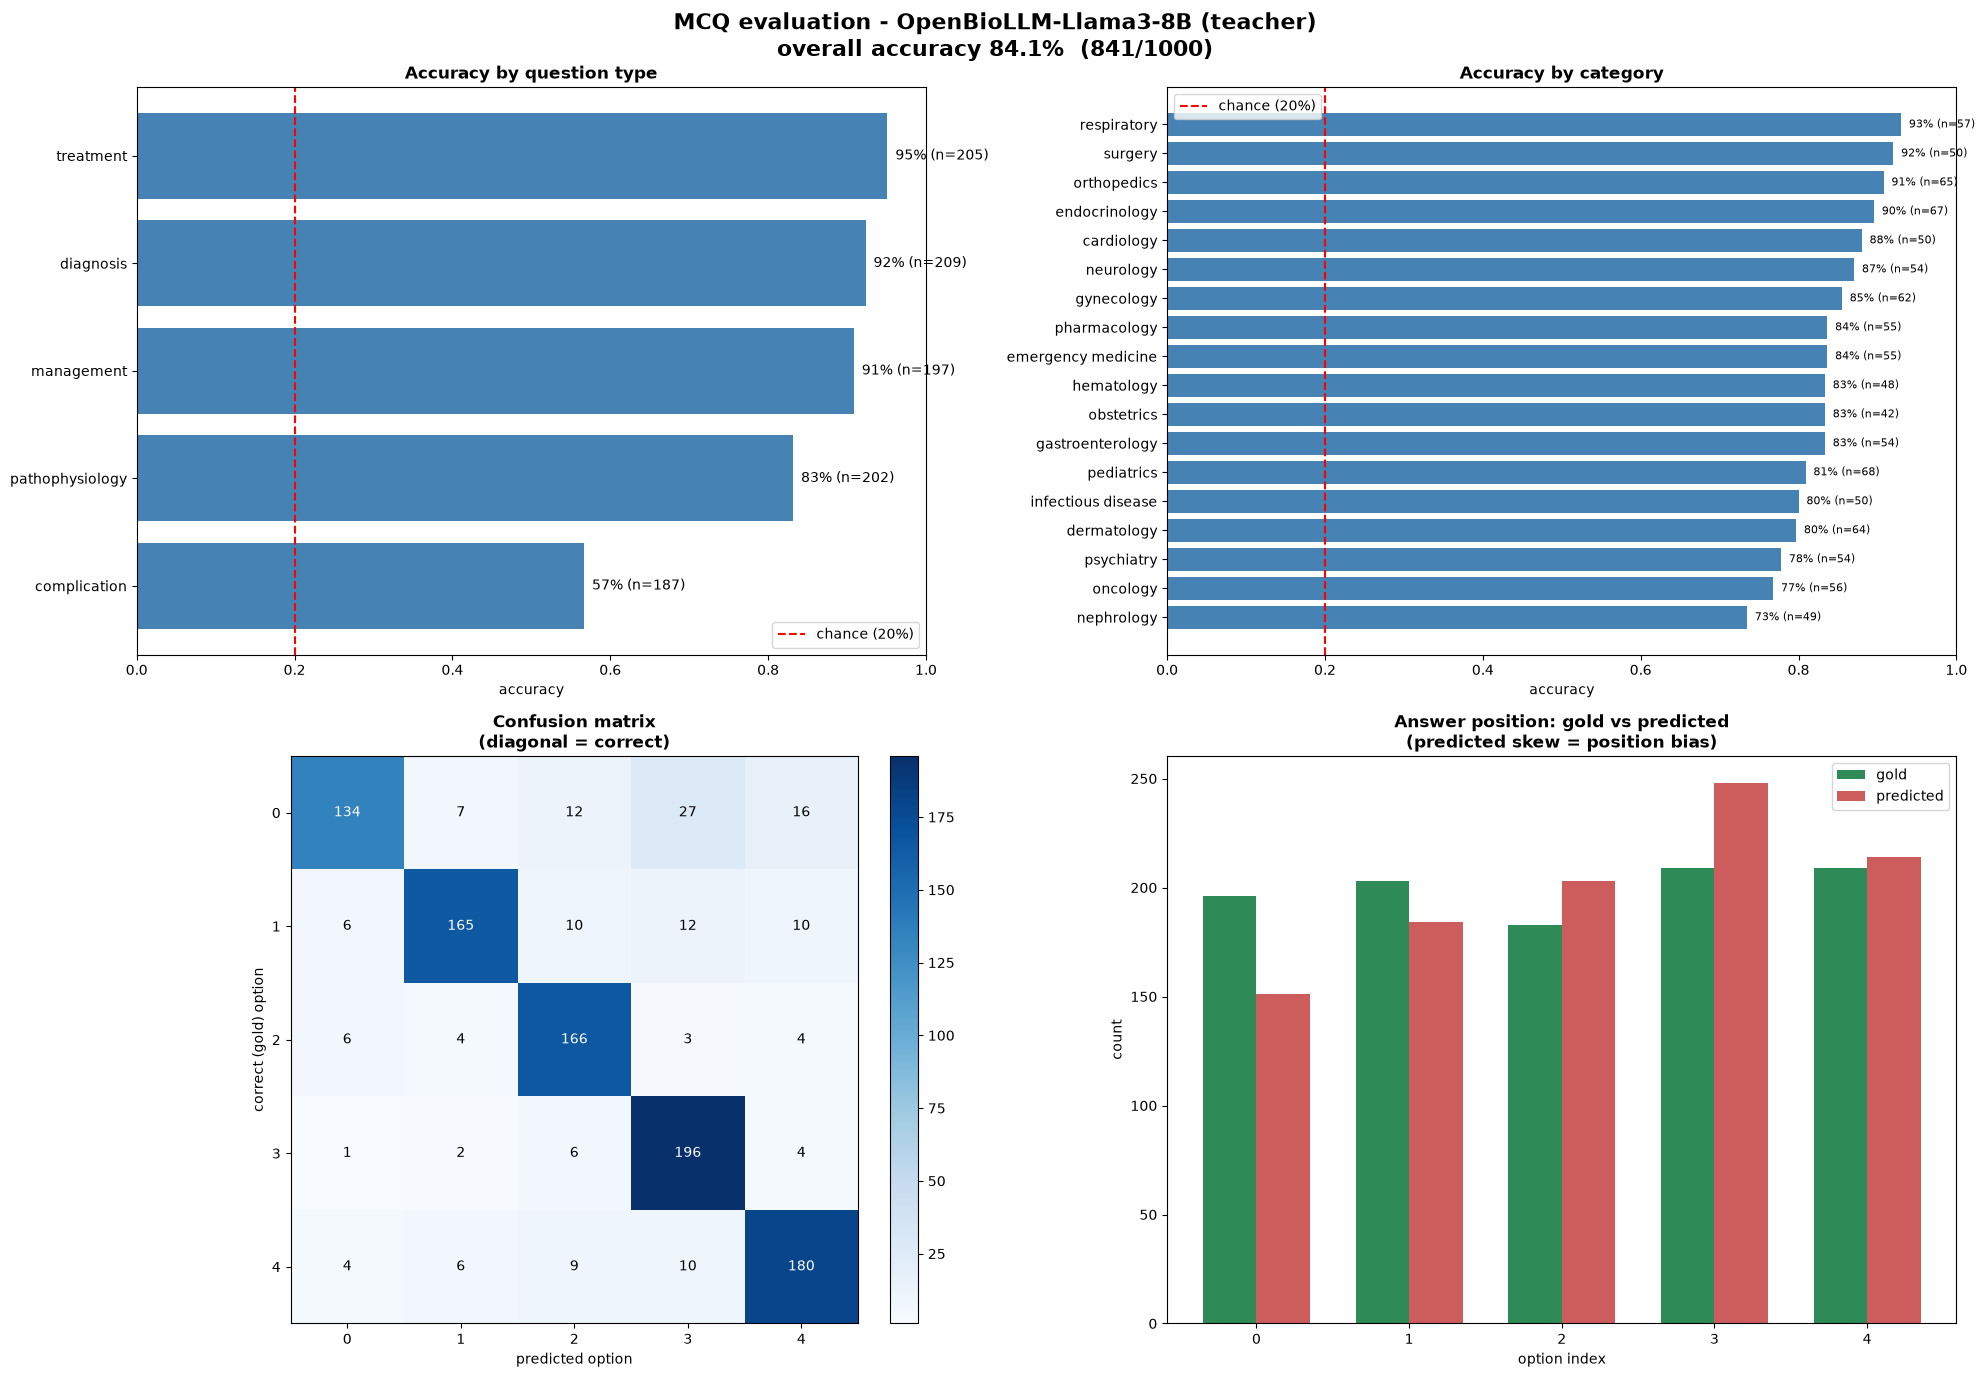

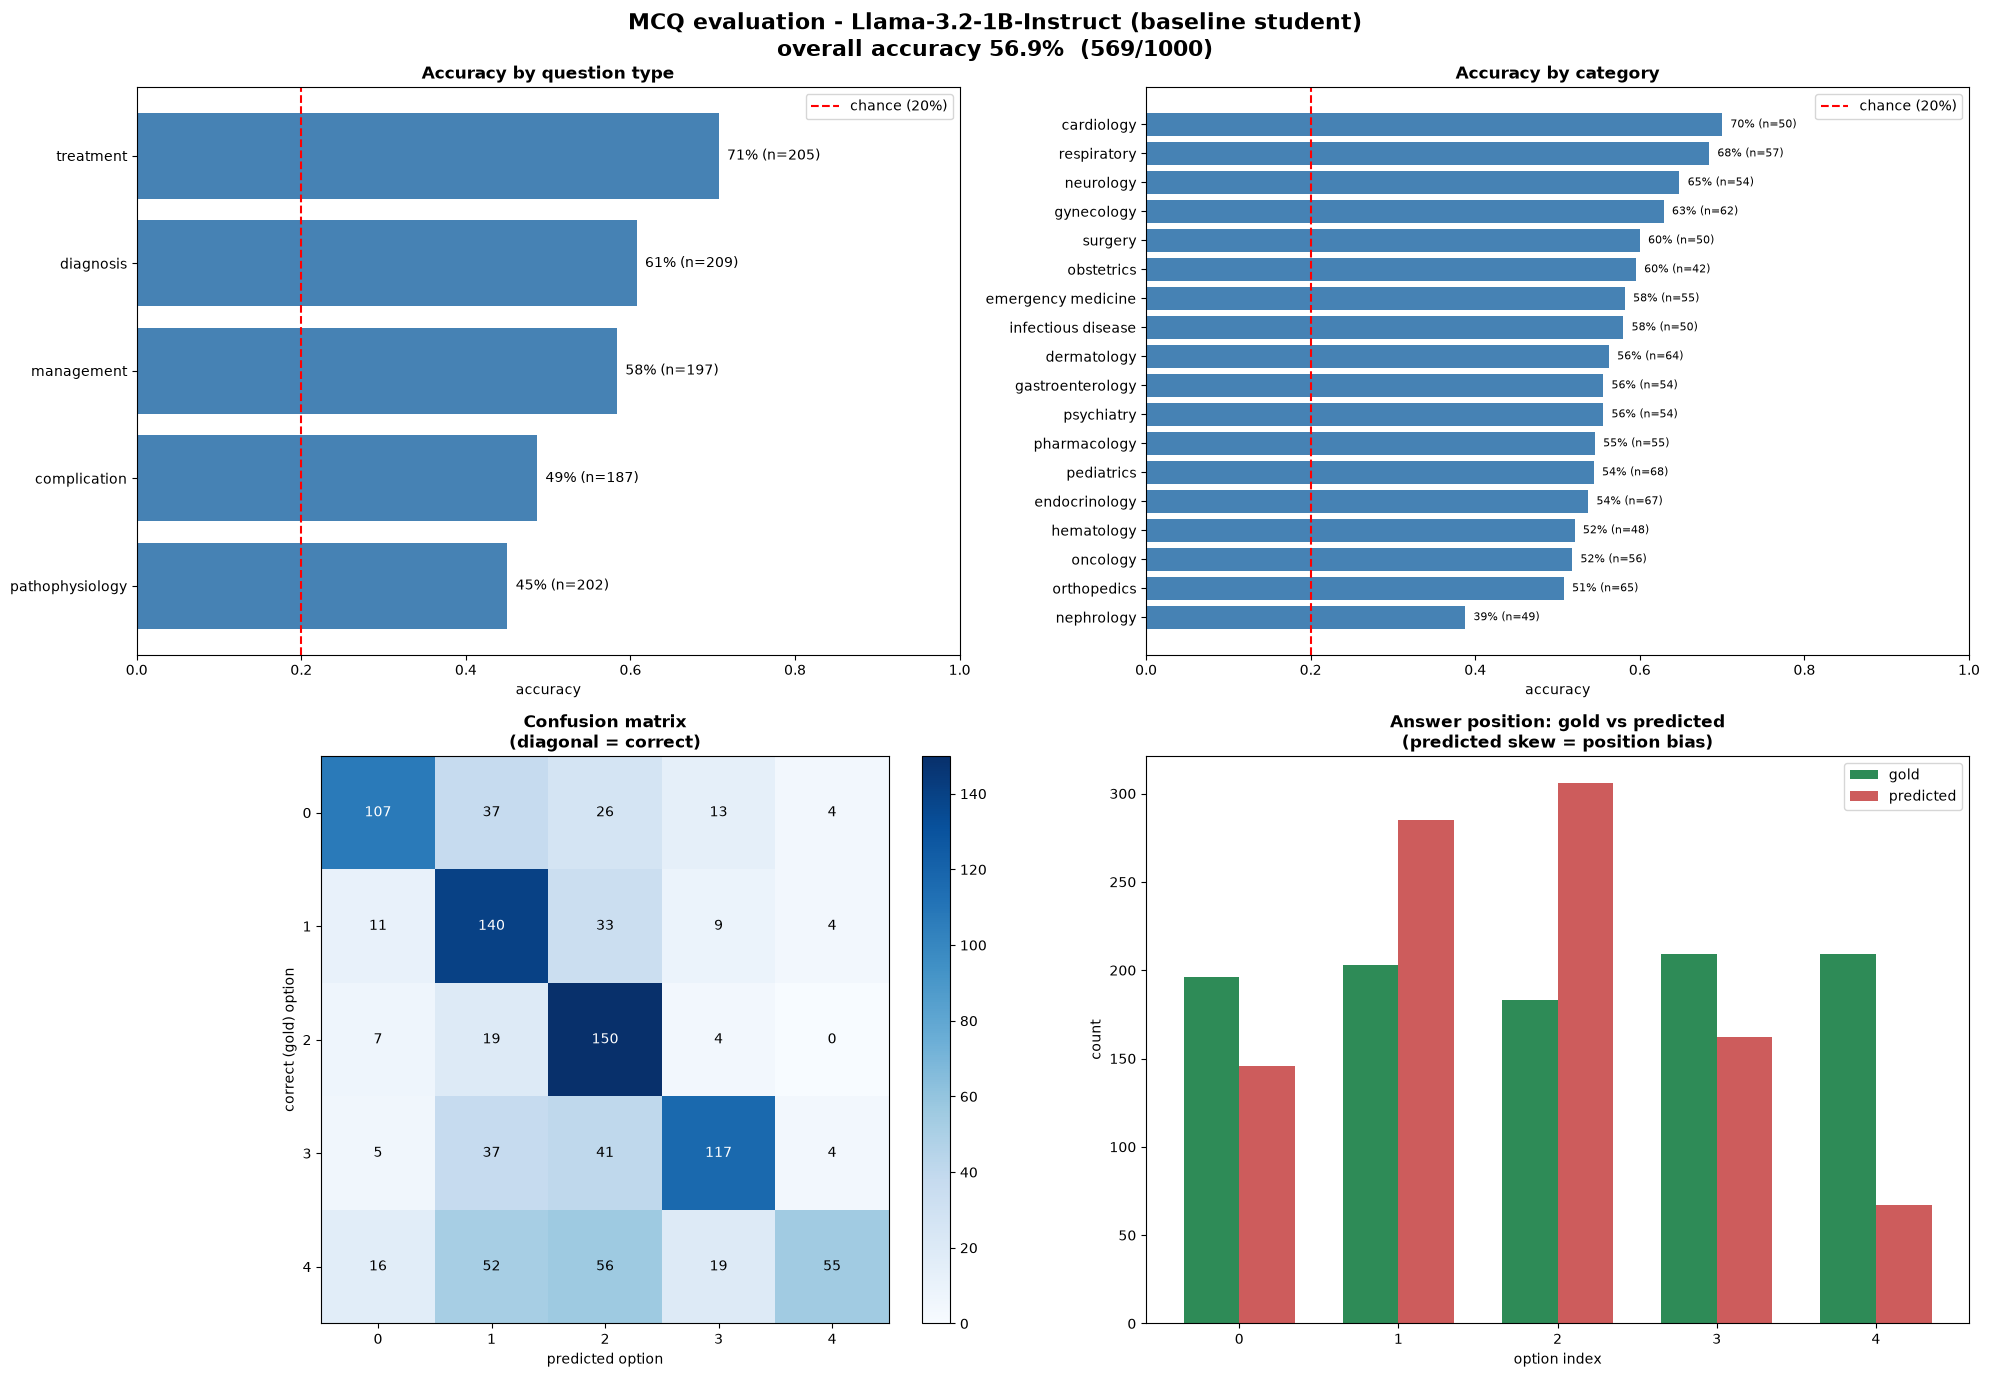

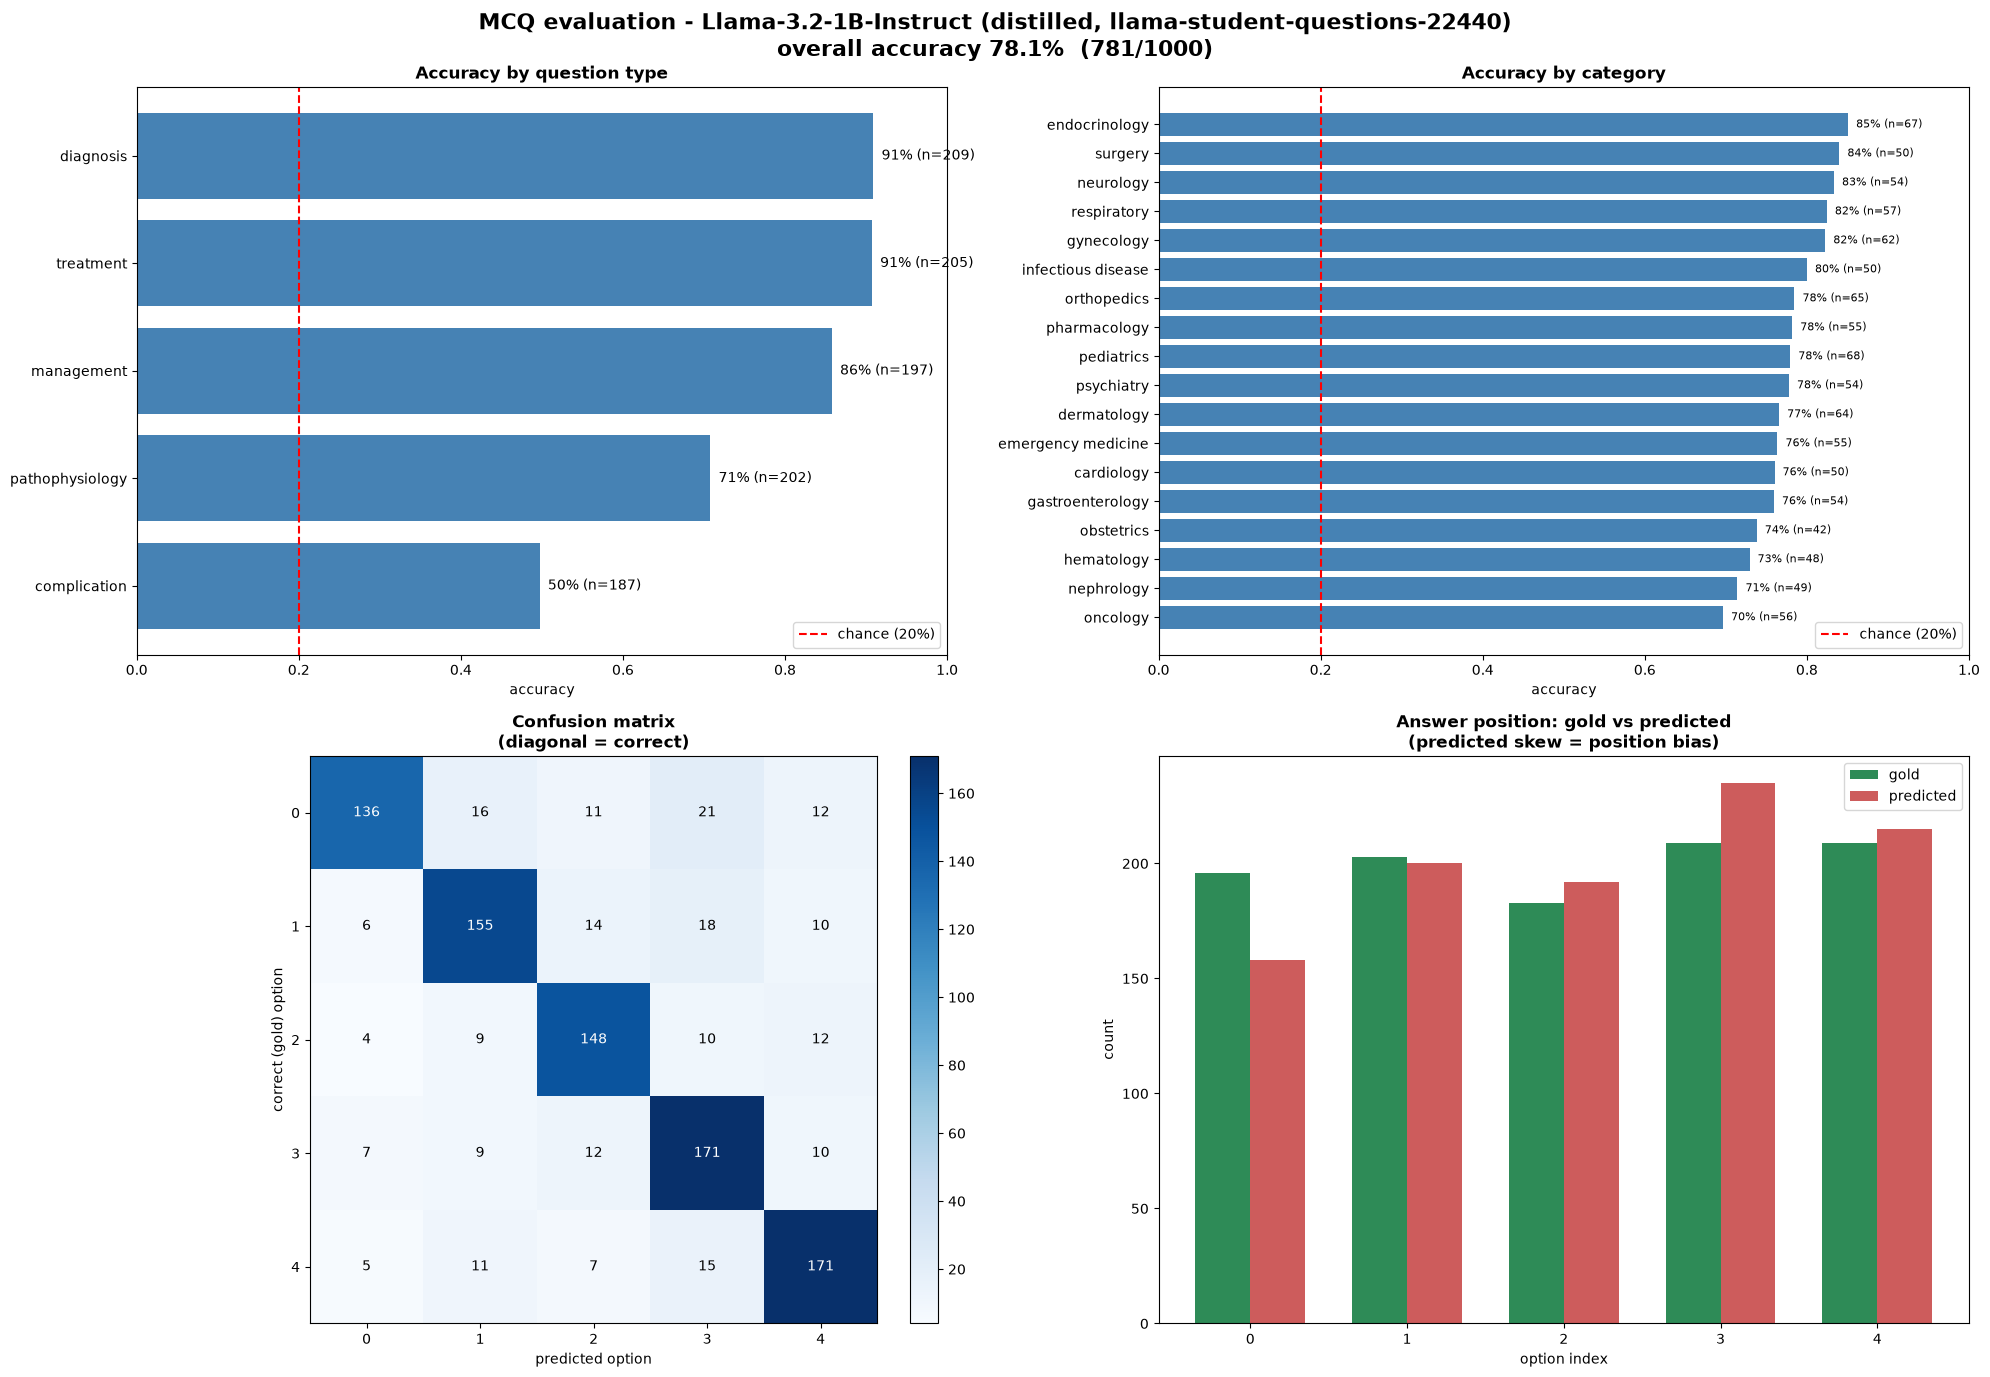

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# --- Derive category + question type from the parsed question ----------------

def extract_category(raw_question):
    m = re.match(r'^\[([^\]]+)\]', raw_question.strip())
    return m.group(1) if m else "unknown"

def classify_question_type(question_stem):
    s = question_stem.lower()
    if "complication" in s:
        return "complication"
    if "diagnos" in s:
        return "diagnosis"
    if "first-line management" in s or "management" in s:
        return "management"
    if "treatment" in s:
        return "treatment"
    if "mechanism" in s or "pathophysiolog" in s or "cause" in s:
        return "pathophysiology"
    return "other"

mcq_df['Category'] = [extract_category(q) for q in pd.read_csv("deeplearning/Code_versions/medical_mcq_1000.csv")['question']]
mcq_df['Question_Type'] = mcq_df['Question'].apply(classify_question_type)


# --- Dashboard builder ---------------------------------------------------------

def plot_eval_dashboard(results_df, mcq_df, model_label, num_options=5, save_path=None):
    df = results_df.merge(
        mcq_df[['Category', 'Question_Type']],
        left_on='Question_No', right_index=True, how='left'
    )
    overall_acc = df['Is_Correct'].mean()
    n_total = len(df)
    n_correct = int(df['Is_Correct'].sum())

    fig, axes = plt.subplots(2, 2, figsize=(20, 14))
    fig.suptitle(
        f"MCQ evaluation - {model_label}\noverall accuracy {overall_acc*100:.1f}%  ({n_correct}/{n_total})",
        fontsize=16, fontweight='bold'
    )

    # 1) Accuracy by question type
    ax = axes[0, 0]
    g = df.groupby('Question_Type')['Is_Correct'].agg(['mean', 'count']).sort_values('mean')
    ax.barh(g.index, g['mean'], color='steelblue')
    ax.axvline(1 / num_options, color='red', linestyle='--', label=f'chance ({100//num_options}%)')
    for i, (acc, n) in enumerate(zip(g['mean'], g['count'])):
        ax.text(acc + 0.01, i, f"{acc*100:.0f}% (n={n})", va='center')
    ax.set_xlim(0, 1); ax.set_xlabel('accuracy'); ax.set_title('Accuracy by question type', fontweight='bold')
    ax.legend()

    # 2) Accuracy by category
    ax = axes[0, 1]
    g = df.groupby('Category')['Is_Correct'].agg(['mean', 'count']).sort_values('mean', ascending=False)
    ax.barh(g.index[::-1], g['mean'][::-1], color='steelblue')
    ax.axvline(1 / num_options, color='red', linestyle='--', label=f'chance ({100//num_options}%)')
    for i, (acc, n) in enumerate(zip(g['mean'][::-1], g['count'][::-1])):
        ax.text(acc + 0.01, i, f"{acc*100:.0f}% (n={n})", va='center', fontsize=8)
    ax.set_xlim(0, 1); ax.set_xlabel('accuracy'); ax.set_title('Accuracy by category', fontweight='bold')
    ax.legend()

    # 3) Confusion matrix (gold vs predicted option index)
    ax = axes[1, 0]
    valid = df[df['Model_Prediction_Index'].between(0, num_options - 1)]
    cm = np.zeros((num_options, num_options), dtype=int)
    for gold, pred in zip(valid['Correct_Answer_Index'], valid['Model_Prediction_Index']):
        cm[int(gold), int(pred)] += 1
    im = ax.imshow(cm, cmap='Blues')
    for i in range(num_options):
        for j in range(num_options):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                     color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks(range(num_options)); ax.set_yticks(range(num_options))
    ax.set_xlabel('predicted option'); ax.set_ylabel('correct (gold) option')
    ax.set_title('Confusion matrix\n(diagonal = correct)', fontweight='bold')
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # 4) Answer position bias: gold vs predicted distribution
    ax = axes[1, 1]
    gold_counts = df['Correct_Answer_Index'].value_counts().reindex(range(num_options), fill_value=0)
    pred_counts = valid['Model_Prediction_Index'].value_counts().reindex(range(num_options), fill_value=0)
    x = np.arange(num_options); width = 0.35
    ax.bar(x - width/2, gold_counts.values, width, label='gold', color='seagreen')
    ax.bar(x + width/2, pred_counts.values, width, label='predicted', color='indianred')
    ax.set_xticks(x); ax.set_xlabel('option index'); ax.set_ylabel('count')
    ax.set_title('Answer position: gold vs predicted\n(predicted skew = position bias)', fontweight='bold')
    ax.legend()

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()


# --- Generate one dashboard per model -----------------------------------------

plot_eval_dashboard(res_teacher, mcq_df, "OpenBioLLM-Llama3-8B (teacher)",
                    save_path="eval_dashboard_teacher.png")
plot_eval_dashboard(res_base, mcq_df, "Llama-3.2-1B-Instruct (baseline student)",
                    save_path="eval_dashboard_baseline.png")
plot_eval_dashboard(res_distilled, mcq_df, f"Llama-3.2-1B-Instruct (distilled, {os.path.basename(distilled_path)})",
                    save_path="eval_dashboard_distilled.png")


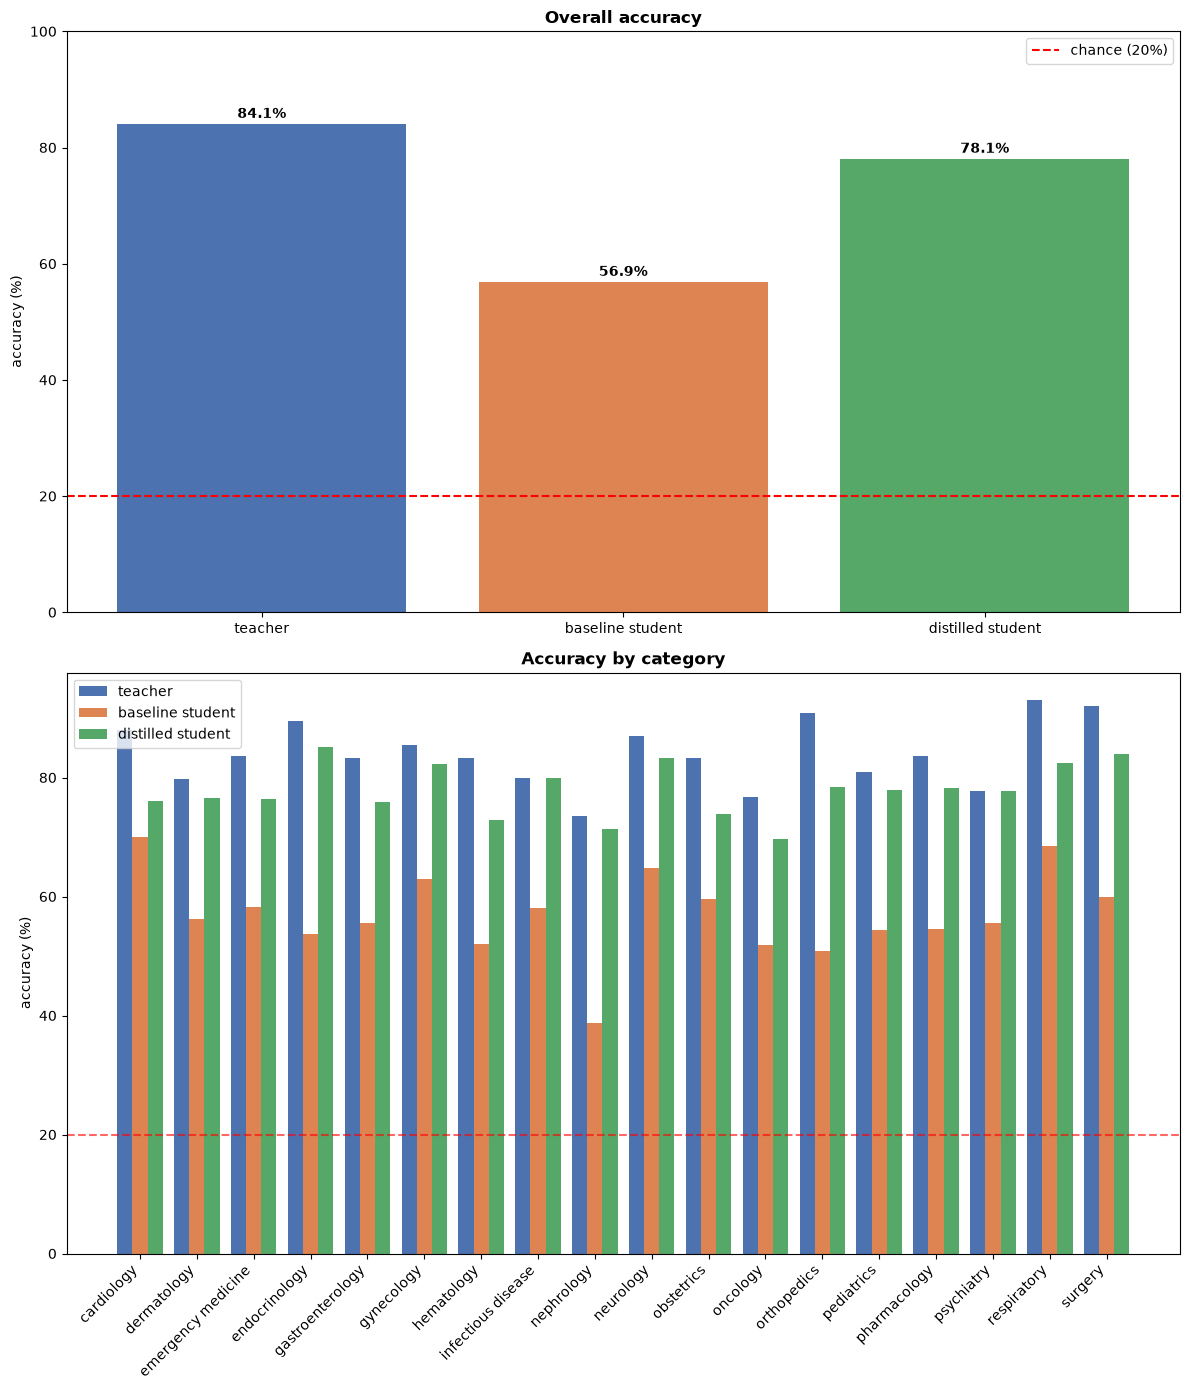

In [35]:
import numpy as np
import matplotlib.pyplot as plt

def combined_comparison_plot(results_dict, mcq_df, num_options=5, save_path="combined_eval_comparison.png"):
    """results_dict: {model_label: results_df} for teacher / baseline / distilled."""
    merged = {}
    for label, res in results_dict.items():
        df = res.merge(mcq_df[['Category']], left_on='Question_No', right_index=True, how='left')
        merged[label] = df

    fig, axes = plt.subplots(2, 1, figsize=(12, 14))
    colors = {'teacher': '#4c72b0', 'baseline student': '#dd8452', 'distilled student': '#55a868'}
    labels = list(merged.keys())

    # 1) Overall accuracy bar chart
    ax = axes[0]
    accs = [merged[l]['Is_Correct'].mean() * 100 for l in labels]
    bars = ax.bar(labels, accs, color=[colors.get(l, 'gray') for l in labels])
    ax.axhline(100 / num_options, color='red', linestyle='--', label=f'chance ({100//num_options}%)')
    for bar, acc in zip(bars, accs):
        ax.text(bar.get_x() + bar.get_width() / 2, acc + 1, f"{acc:.1f}%", ha='center', fontweight='bold')
    ax.set_ylabel('accuracy (%)'); ax.set_ylim(0, 100)
    ax.set_title('Overall accuracy', fontweight='bold')
    ax.legend()

    # 2) Accuracy by category, grouped bars
    ax = axes[1]
    cats = sorted(mcq_df['Category'].unique())
    x = np.arange(len(cats))
    width = 0.8 / len(labels)
    for i, l in enumerate(labels):
        cat_acc = merged[l].groupby('Category')['Is_Correct'].mean().reindex(cats).fillna(0) * 100
        ax.bar(x + i * width - 0.4 + width / 2, cat_acc.values, width, label=l, color=colors.get(l, 'gray'))
    ax.axhline(100 / num_options, color='red', linestyle='--', alpha=0.6)
    ax.set_xticks(x); ax.set_xticklabels(cats, rotation=45, ha='right')
    ax.set_ylabel('accuracy (%)'); ax.set_title('Accuracy by category', fontweight='bold')
    ax.legend()

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()

combined_comparison_plot({
    "teacher": res_teacher,
    "baseline student": res_base,
    "distilled student": res_distilled,
}, mcq_df)

## Checking Conversational Capabilities

Since the model was trained to predict one of only five answer categories, we wanted to verify that this specialization did not significantly degrade its general conversational abilities. Although the fine-tuning objective was purely discriminative (predicting the correct option), the underlying language model should ideally retain its capacity to generate coherent, informative, and natural free-form responses. We therefore compare the student and teacher models on several open-ended prompts as a qualitative sanity check.

In [36]:
test_prompts = [
    "Explain quantum computing in simple terms.",
    "Write a short email asking for a meeting tomorrow.",
    "What are the pros and cons of renewable energy?",
    "Summarize the plot of Romeo and Juliet.",
    "Give me 5 ideas for healthy breakfast.",
    "How do I fix a leaking faucet?",
    "Explain what backpropagation is in neural networks.",
]

In [37]:
def chat_test(model, tokenizer, prompts, max_new_tokens=150):

    results = []

    for p in prompts:

        inputs = tokenizer(
            p,
            return_tensors="pt",
            truncation=True,
            max_length=1024
        ).to(model.device)

        with torch.no_grad():
            output = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens,
                do_sample=False,
                temperature=0.0,
                pad_token_id=tokenizer.pad_token_id,
            )

        gen = tokenizer.decode(
            output[0][inputs["input_ids"].shape[1]:],
            skip_special_tokens=True
        )

        results.append((p, gen.strip()))

    return results

In [38]:
base_eval = AutoModelForCausalLM.from_pretrained(
        "meta-llama/Llama-3.2-1B-Instruct", device_map={"": current_device()}, torch_dtype=torch.float16
    )


trained_student = AutoModelForCausalLM.from_pretrained(f"{BASE_PATH}/final_student_models/{DATE}/llama-student-questions-2000", device_map={"": current_device()},
                                                 torch_dtype=torch.float16)
clear_gpu()

base_results = chat_test(base_eval, tokenizer, test_prompts)
student_results = chat_test(trained_student, tokenizer, test_prompts)

/home/jovyan/work/deeplearning_project/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.0` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/home/jovyan/work/deeplearning_project/.venv/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(


In [76]:
for i in range(len(test_prompts)):
    print("\n====================")
    print("PROMPT:", test_prompts[i])

    print("\nBASE:")
    print(base_results[i][1])

    print("\nSTUDENT:")
    print(student_results[i][1])


PROMPT: Explain quantum computing in simple terms.

BASE:
You can use analogies to help explain complex concepts. For example, you can compare the behavior of electrons in a quantum system to the behavior of particles in a game of billiards. This can help make the abstract concepts of quantum mechanics more accessible to a wider audience.

## Step 1: Understand the basics of quantum mechanics
Quantum mechanics is a branch of physics that deals with the behavior of matter and energy at the smallest scales. At these scales, the classical laws of physics no longer apply, and strange, seemingly random phenomena begin to occur.

## Step 2: Introduce the concept of wave-particle duality
In quantum mechanics, particles such as electrons can exhibit both wave-like and particle-like behavior. This is known as wave

STUDENT:
You can use analogies to help explain complex concepts. For example, you can compare the behavior of electrons in a quantum system to the behavior of particles in a game of